# 01 — Fire history EDA (NASA FIRMS, Greece)

**Goal:** understand *when* and *where* vegetation fires occur in Greece (2012 onwards) and use that to choose the study area for the risk model.

**Data:** NASA FIRMS active-fire detections from the VIIRS S-NPP sensor (375 m pixels), downloaded with `python -m src.download_firms`.

In [1]:
from pathlib import Path

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Project root = the first folder (going upwards) that contains environment.yml,
# so paths work no matter where the notebook is run from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists())
RAW_DIR = ROOT / "data" / "raw"
FIG_DIR = ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIRE_COLOR = "#eb6834"  # one hue for every fire chart in the project

# Clean, recessive chart style
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

## 1. Load the data

In [2]:
files = sorted((RAW_DIR / "firms").glob("*.csv"))
print(f"{len(files)} yearly files found")

fires_raw = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)
print(f"{len(fires_raw):,} detections in total")
fires_raw.head()

14 yearly files found
90,442 detections in total


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,38.87734,22.51873,326.05,0.45,0.47,2012-01-20,1055,N,VIIRS,n,2,286.82,1.66,D,0
1,38.87963,22.52029,346.50,0.45,0.47,2012-01-20,1055,N,VIIRS,n,2,288.07,5.26,D,0
2,38.88662,22.33008,335.32,0.46,0.47,2012-01-20,1055,N,VIIRS,n,2,287.80,3.05,D,0
3,38.87539,22.53038,336.26,0.45,0.47,2012-01-20,1055,N,VIIRS,n,2,287.13,7.93,D,0
4,39.13734,26.24353,328.77,0.46,0.39,2012-01-20,1055,N,VIIRS,n,2,278.18,3.84,D,0


In [3]:
fires_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 90442 entries, 0 to 90441
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   latitude    90442 non-null  float64
 1   longitude   90442 non-null  float64
 2   bright_ti4  90442 non-null  float64
 3   scan        90442 non-null  float64
 4   track       90442 non-null  float64
 5   acq_date    90442 non-null  str    
 6   acq_time    90442 non-null  int64  
 7   satellite   90442 non-null  str    
 8   instrument  90442 non-null  str    
 9   confidence  90442 non-null  str    
 10  version     90442 non-null  int64  
 11  bright_ti5  90442 non-null  float64
 12  frp         90442 non-null  float64
 13  daynight    90442 non-null  str    
 14  type        90442 non-null  int64  
dtypes: float64(7), int64(3), str(5)
memory usage: 10.4 MB


**What the main columns mean**

| Column | Meaning |
|---|---|
| `latitude`, `longitude` | centre of the 375 m pixel where heat was detected |
| `acq_date`, `acq_time` | date and UTC time (HHMM) of the satellite pass |
| `confidence` | detection confidence: `l` low, `n` nominal, `h` high |
| `frp` | Fire Radiative Power (MW), a measure of fire intensity |
| `daynight` | `D` day / `N` night pass |
| `type` | 0 = presumed vegetation fire, 1 = volcano, 2 = other static land source (factories, gas flares), 3 = offshore |

⚠️ A **detection is not a fire**: a large fire burning for days produces hundreds of detections. We keep this in mind when comparing regions.

## 2. Cleaning

We keep only what we want the model to learn:
1. **Vegetation fires** (`type == 0`): industrial heat sources burn every day at the same spot and would teach the model nothing about wildfire risk.
2. **Nominal or high confidence**: low-confidence detections are more likely to be false alarms (e.g. sun glint, hot surfaces).

In [4]:
print("Confidence values:", fires_raw["confidence"].value_counts().to_dict())
if "type" in fires_raw.columns:
    print("Type values:", fires_raw["type"].value_counts().to_dict())

Confidence values: {'n': 79799, 'h': 5581, 'l': 5062}
Type values: {0: 75145, 2: 13508, 3: 1789}


In [5]:
fires = fires_raw.copy()
fires["acq_date"] = pd.to_datetime(fires["acq_date"])
fires["year"] = fires["acq_date"].dt.year
fires["month"] = fires["acq_date"].dt.month
n_start = len(fires)

# 1. Keep presumed vegetation fires only
if "type" in fires.columns:
    fires = fires[fires["type"] == 0]
    print(f"After keeping vegetation fires: {len(fires):,}")
else:
    print("No 'type' column in this file version, filter skipped")

# 2. Drop low-confidence detections (first letter handles both 'l' and 'low')
is_low = fires["confidence"].astype(str).str.lower().str[0] == "l"
fires = fires[~is_low]
print(f"After dropping low confidence: {len(fires):,} ({len(fires) / n_start:.0%} of the original)")

After keeping vegetation fires: 75,145
After dropping low confidence: 70,197 (78% of the original)


Next we turn the table into a **GeoDataFrame**: a pandas table with a `geometry` column (here, points), so we can map it and do spatial joins.

`EPSG:4326` is the coordinate reference system (CRS) of plain latitude/longitude in degrees, which is what FIRMS gives us.

In [6]:
gfires = gpd.GeoDataFrame(
    fires,
    geometry=gpd.points_from_xy(fires["longitude"], fires["latitude"]),
    crs="EPSG:4326",
)
gfires[["acq_date", "confidence", "frp", "geometry"]].head()

,acq_date,confidence,frp,geometry
0,2012-01-20,n,1.66,POINT (22.51873 38.87734)
1,2012-01-20,n,5.26,POINT (22.52029 38.87963)
2,2012-01-20,n,3.05,POINT (22.33008 38.88662)
3,2012-01-20,n,7.93,POINT (22.53038 38.87539)
4,2012-01-20,n,3.84,POINT (26.24353 39.13734)


## 3. When do fires happen?

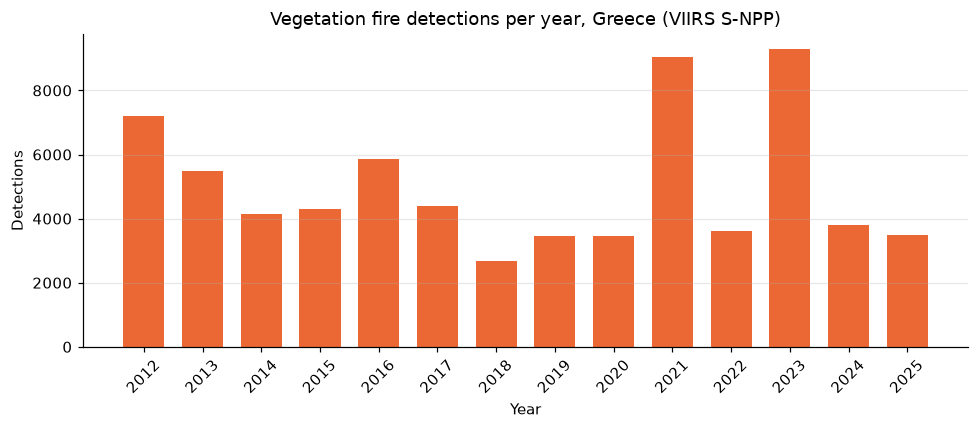

In [7]:
per_year = gfires.groupby("year").size()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(per_year.index, per_year.values, color=FIRE_COLOR, width=0.7)
ax.set_title("Vegetation fire detections per year, Greece (VIIRS S-NPP)")
ax.set_xlabel("Year")
ax.set_ylabel("Detections")
ax.set_xticks(per_year.index)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fires_per_year.png")
plt.show()

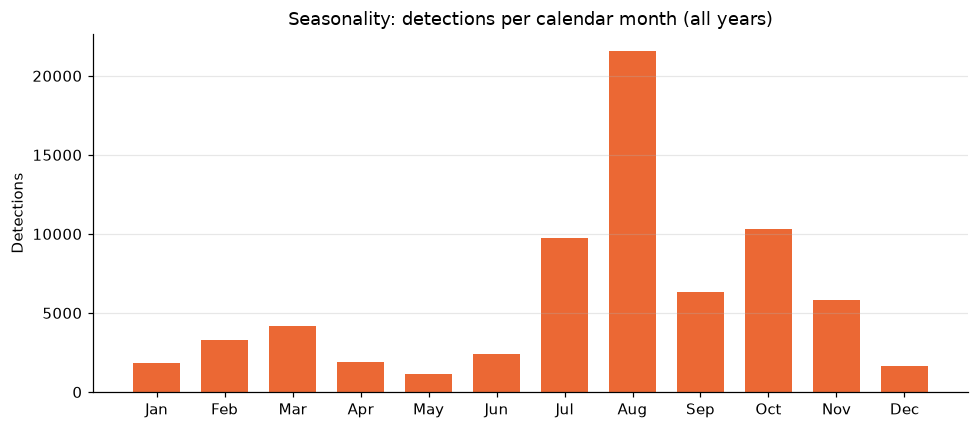

In [8]:
per_month = gfires.groupby("month").size().reindex(range(1, 13), fill_value=0)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(month_names, per_month.values, color=FIRE_COLOR, width=0.7)
ax.set_title("Seasonality: detections per calendar month (all years)")
ax.set_ylabel("Detections")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fires_per_month.png")
plt.show()

**Observations:** *(fill in after running: which years stand out, and which months make up the fire season?)*

## 4. Where do fires happen?

To draw the points over a web basemap we reproject to **EPSG:3857** (Web Mercator, in metres), the CRS that map tiles use.

We use a **hexbin** map: we count detections inside hexagons, which shows density far better than plotting tens of thousands of overlapping dots. The colour scale is **logarithmic** because a few mega-fires would otherwise hide everything else.

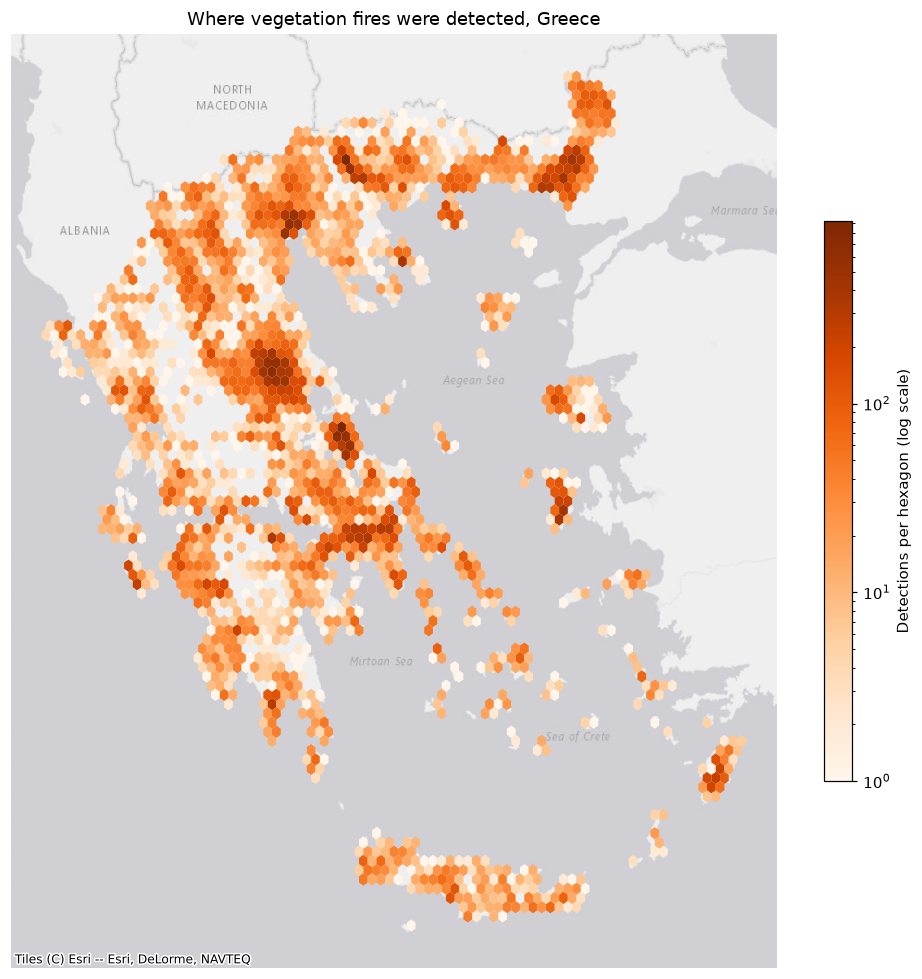

In [14]:
gfires_3857 = gfires.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(9, 9))
hb = ax.hexbin(
    gfires_3857.geometry.x,
    gfires_3857.geometry.y,
    gridsize=80,
    bins="log",       # logarithmic colour scale
    mincnt=1,         # leave empty hexagons transparent
    cmap="Oranges",   # one hue, light -> dark = few -> many
    linewidths=0,
)
cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas)
fig.colorbar(hb, ax=ax, shrink=0.6, label="Detections per hexagon (log scale)")
ax.set_title("Where vegetation fires were detected, Greece")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG_DIR / "fire_density_map.png")
plt.show()

## 5. Which region should we model?

We count detections per administrative region using boundaries from **Natural Earth** (a free public map dataset), via a **spatial join**: each fire point gets the name of the region polygon it falls in.

Raw detection counts favour regions with one huge fire, so we also look at:
- `fire_days`: on how many different days a fire was detected, a proxy for how *often* fires happen
- `years_with_fire`: in how many years the region had fires
- `share_of_biggest_year`: what share of all detections came from the single worst year (high = dominated by one event)

In [10]:
# Download the Natural Earth admin-1 boundaries once and cache them in data/raw
NE_URL = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip"
ne_path = RAW_DIR / "ne_10m_admin_1_states_provinces.zip"
if not ne_path.exists():
    ne_path.write_bytes(requests.get(NE_URL, timeout=120).content)

regions = gpd.read_file(ne_path)
regions = regions.loc[regions["admin"] == "Greece", ["name", "geometry"]].to_crs("EPSG:4326")
print(f"{len(regions)} regions:", sorted(regions["name"]))

14 regions: ['Anatoliki Makedonia kai Thraki', 'Attiki', 'Ayion Oros', 'Dytiki Ellada', 'Dytiki Makedonia', 'Ionioi Nisoi', 'Ipeiros', 'Kentriki Makedonia', 'Kriti', 'Notio Aigaio', 'Peloponnisos', 'Stereá Elláda', 'Thessalia', 'Voreio Aigaio']


In [11]:
# Spatial join: attach the region name to every fire point that falls inside a region
joined = gpd.sjoin(gfires, regions, how="inner", predicate="within")

per_region = joined.groupby("name").agg(
    detections=("geometry", "size"),
    fire_days=("acq_date", "nunique"),
    years_with_fire=("year", "nunique"),
)

by_region_year = joined.groupby(["name", "year"]).size().unstack(fill_value=0)
per_region["share_of_biggest_year"] = (by_region_year.max(axis=1) / by_region_year.sum(axis=1)).round(2)

per_region = per_region.sort_values("fire_days", ascending=False)
per_region

,detections,fire_days,years_with_fire,share_of_biggest_year
name,,,,
Kentriki Makedonia,10916,1855,14,0.11
Thessalia,11438,1569,14,0.15
Anatoliki Makedonia kai Thraki,9698,1220,14,0.47
Stereá Elláda,9336,1210,14,0.46
Dytiki Ellada,3249,1062,14,0.15
Dytiki Makedonia,3997,1002,14,0.15
Peloponnisos,4331,896,14,0.29
Kriti,2326,757,14,0.15
Attiki,4627,662,14,0.30


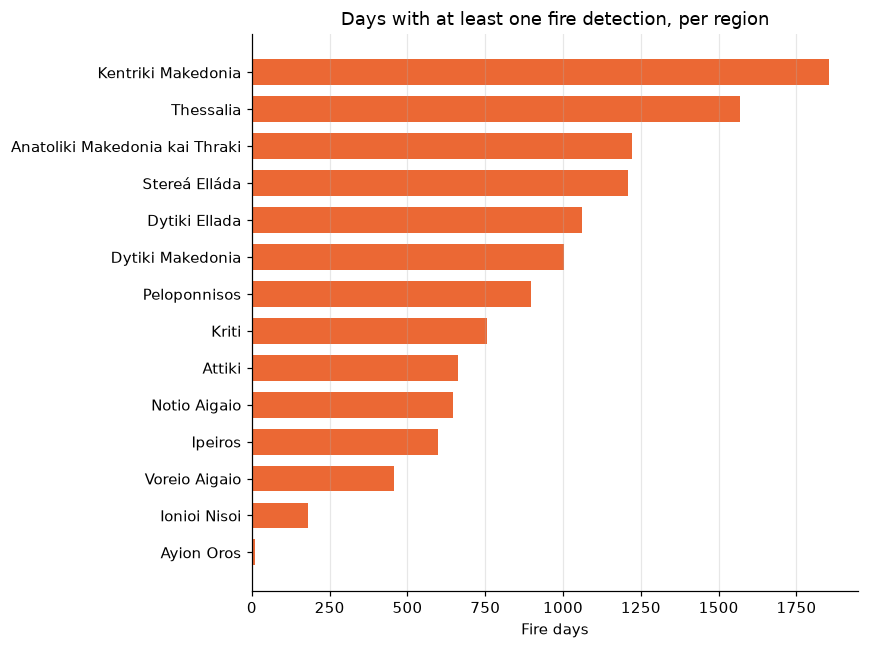

In [12]:
top = per_region.sort_values("fire_days")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["fire_days"], color=FIRE_COLOR, height=0.7)
ax.set_title("Days with at least one fire detection, per region")
ax.set_xlabel("Fire days")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fire_days_per_region.png")
plt.show()

## 6. Choice of study area

**Criteria** for a good study area:
1. Many fire days spread over many years, so the model sees enough positive examples in every year (we will split train/test **by year**).
2. Not dominated by one extreme year.
3. A mix of burned and unburned land, so the model has something to tell apart.
4. A manageable size, so satellite and weather downloads stay fast.

**Decision: Attica (Attiki).** 85% of its detections fall in June–September, so labels are mostly real wildfires rather than agricultural burning; it has ~368 summer fire days and no single year dominates (max 30% of detections); and its small size keeps satellite and weather downloads fast. Caveat: a large urban area, to be filtered out with land-cover data in Session 2.

In [15]:
# Wildfires peak in summer; agricultural burning happens mostly outside it.
# A low summer share hints that a region's detections are dominated by crop burning.
joined["is_summer"] = joined["month"].between(6, 9)

summer_days = joined[joined["is_summer"]].groupby("name")["acq_date"].nunique()

season = per_region[["fire_days", "share_of_biggest_year"]].copy()
season["summer_fire_days"] = summer_days.reindex(season.index, fill_value=0)
season["summer_share_of_detections"] = joined.groupby("name")["is_summer"].mean()

season.sort_values("summer_fire_days", ascending=False).round(2)

,fire_days,share_of_biggest_year,summer_fire_days,summer_share_of_detections
name,,,,
Thessalia,1569,0.15,761,0.60
Kentriki Makedonia,1855,0.11,576,0.17
Stereá Elláda,1210,0.46,406,0.76
Dytiki Ellada,1062,0.15,375,0.52
Attiki,662,0.30,368,0.85
Peloponnisos,896,0.29,347,0.71
Anatoliki Makedonia kai Thraki,1220,0.47,334,0.61
Dytiki Makedonia,1002,0.15,302,0.33
Kriti,757,0.15,230,0.52
